## Soveltava matematiikka ja fysiikka ohjelmoinnissa, harjoitukset 9.11.2026

In [20]:
# Tee noin 20 sekunnin mittaukset kolmella saatavilla olevalla sensorilla, esimerkiksi kiihtyvyysanturilla, magnetometrillä ja GPS:llä.
# a) Laske peräkkäisten havaintojen aikavälit ja tutki, ovatko ne vakioita.
# b) Laske koko mittauksen keskimääräinen näytteenottotaajuus  
# c) Laske yksittäisiä aikavälejä vastaavat taajuudet f. Määritä niiden pienin ja suurin arvo. Tarkista ensin, ovatko kaikki aikavälit positiivisia, ja selvitä mahdolliset poikkeamat.
# d) Piirrä aikaväleistä laskettujen taajuuksien histogrammit eri sensoreille. Vertaa tuloksia.

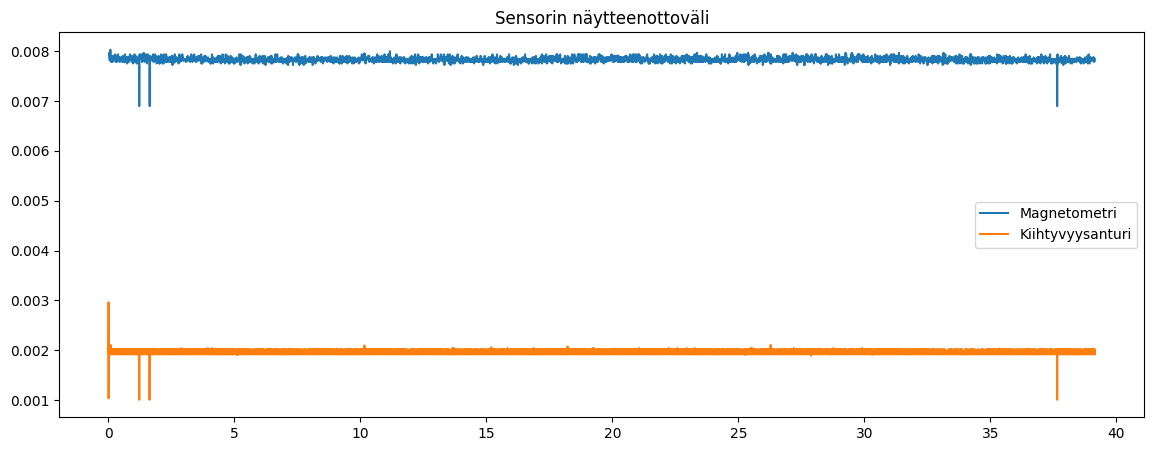

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_acc = pd.read_csv('./Data/Accelerometer.csv') #Time (s)	Acceleration x (m/s^2)	Acceleration y (m/s^2)	Acceleration z (m/s^2)
df_loc = pd.read_csv('./Data/Location.csv') #	Time (s)	Latitude (°)	Longitude (°)	Height (m)	Velocity (m/s)	Direction (°)	Horizontal Accuracy (m)	Vertical Accuracy (m)
df_mag = pd.read_csv('./Data/Magnetometer.csv') #Time (s)	Magnetic field x (µT)	Magnetic field y (µT)	Magnetic field z (µT)

# a) Laske peräkkäisten havaintojen aikavälit (sampling_time) ja tutki, ovatko ne vakioita.
df_mag['sampling_time'] = df_mag['Time (s)'].diff()
df_loc['sampling_time'] = df_loc['Time (s)'].diff()
df_acc['sampling_time'] = df_acc['Time (s)'].diff()

#Piirretään kuva magnetometrin havaintojen aikaväleistä:
plt.figure(figsize = (14,5))
plt.plot(df_mag['Time (s)'],df_mag['sampling_time'], label = 'Magnetometri')
plt.plot(df_acc['Time (s)'],df_acc['sampling_time'], label = 'Kiihtyvyysanturi')
#plt.plot(df_loc['Time (s)'],df_loc['sampling_time'], label = 'GPS') #GPS:n näytteenottoväli on paljon muita suurempi.
plt.legend()
plt.title('Sensorin näytteenottoväli')
plt.show()
#Johtopäätös:
#Eri sensoreilla on eri näytteenottoväli
# Saman anturin havaintojen näytteenottoväli voi vaihdelle. 

In [22]:
# b) Laske koko mittauksen keskimääräinen näytteenottotaajuus  f_s
#Näytteenottotaajuus on näytteenottovälin käänteisluku, eli näytteiden määrä sekunnissa
f_s_acc = np.round(1/df_acc['sampling_time'].mean(),1)
f_s_mag = np.round(1/df_mag['sampling_time'].mean(),1)
f_s_loc = np.round(1/df_loc['sampling_time'].mean(),1)
print('Kiihtyvyysanturin näytteenottotaajuus on keskimäärin', f_s_acc, 'Hz')
print('Magnetometrinn näytteenottotaajuus on keskimäärin', f_s_mag, 'Hz')
print('GPS-anturin näytteenottotaajuus on keskimäärin', f_s_loc, 'Hz')

Kiihtyvyysanturin näytteenottotaajuus on keskimäärin 510.8 Hz
Magnetometrinn näytteenottotaajuus on keskimäärin 127.7 Hz
GPS-anturin näytteenottotaajuus on keskimäärin 0.1 Hz


In [24]:
# c) Laske yksittäisiä aikavälejä vastaavat taajuudet f. Määritä niiden pienin ja suurin arvo. Tarkista ensin, ovatko kaikki aikavälit positiivisia, ja selvitä mahdolliset poikkeamat.
df_mag['f_s [hz]'] = 1/df_mag['sampling_time']
df_loc['f_s [hz]'] = 1/df_loc['sampling_time']
df_acc['f_s [hz]'] = 1/df_acc['sampling_time']

print('Magnetometer:')
display(df_mag.describe())

print('Location:')
display(df_loc.describe())

print('Acceleration:')
display(df_acc.describe())

# d) Piirrä aikaväleistä laskettujen taajuuksien histogrammit eri sensoreille. Vertaa tuloksia.

Magnetometer:


,Time (s),Magnetic field x (µT),Magnetic field y (µT),Magnetic field z (µT),sampling_time,f_s [hz]
count,4996.000000,4996.000000,4996.000000,4996.000000,4995.000000,4995.000000
mean,19.586520,3.034035,-43.576861,-2.645164,0.007832,127.693894
std,11.296580,39.072053,35.812888,57.088808,0.000047,0.790808
min,0.025927,-88.559998,-118.439995,-139.979996,0.006897,124.593157
25%,9.805237,-12.000000,-61.695000,-35.880001,0.007812,127.501906
50%,19.582662,11.940000,-51.539997,0.690000,0.007843,127.501955
75%,29.368358,21.000000,-16.320000,36.719997,0.007843,128.000000
max,39.144361,95.820000,53.639999,129.839996,0.008026,144.991143


Location:


,Time (s),Latitude (°),Longitude (°),Height (m),Velocity (m/s),Direction (°),Horizontal Accuracy (m),Vertical Accuracy (m),sampling_time,f_s [hz]
count,3.000000,3.000000,3.000000,3.000000e+00,0.0,0.0,3.000000,3.000000,2.000000,2.000000
mean,18.517510,65.073363,25.518239,1.951279e+01,NaN,NaN,73.333333,67.098527,17.693433,0.057498
std,17.743616,0.000001,0.000001,5.427093e-07,NaN,NaN,46.188022,56.987024,3.266481,0.010615
min,0.054160,65.073361,25.518238,1.951279e+01,NaN,NaN,20.000000,1.295580,15.383683,0.049992
25%,10.055752,65.073363,25.518239,1.951279e+01,NaN,NaN,60.000000,50.647790,16.538558,0.053745
50%,20.057344,65.073364,25.518240,1.951279e+01,NaN,NaN,100.000000,100.000000,17.693433,0.057498
75%,27.749185,65.073364,25.518240,1.951279e+01,NaN,NaN,100.000000,100.000000,18.848309,0.061251
max,35.441027,65.073364,25.518240,1.951279e+01,NaN,NaN,100.000000,100.000000,20.003184,0.065004


Acceleration:


,Time (s),Acceleration x (m/s^2),Acceleration y (m/s^2),Acceleration z (m/s^2),sampling_time,f_s [hz]
count,19989.000000,19989.000000,19989.000000,19989.000000,19988.000000,19988.000000
mean,19.582547,0.042315,7.613178,2.906508,0.001958,510.933904
std,11.298559,2.601381,2.341154,4.871187,0.000035,10.568007
min,0.013995,-7.778761,-0.861913,-12.140997,0.001007,337.814442
25%,9.797394,-1.872266,6.713342,-0.117316,0.001923,504.123732
50%,19.578680,-0.311246,8.413225,2.887407,0.001953,512.000000
75%,29.368320,1.529895,9.339781,5.942409,0.001984,520.126287
max,39.148176,11.056423,14.379576,17.571047,0.002960,992.969774


Text(0.5, 1.0, 'f_s GPS')

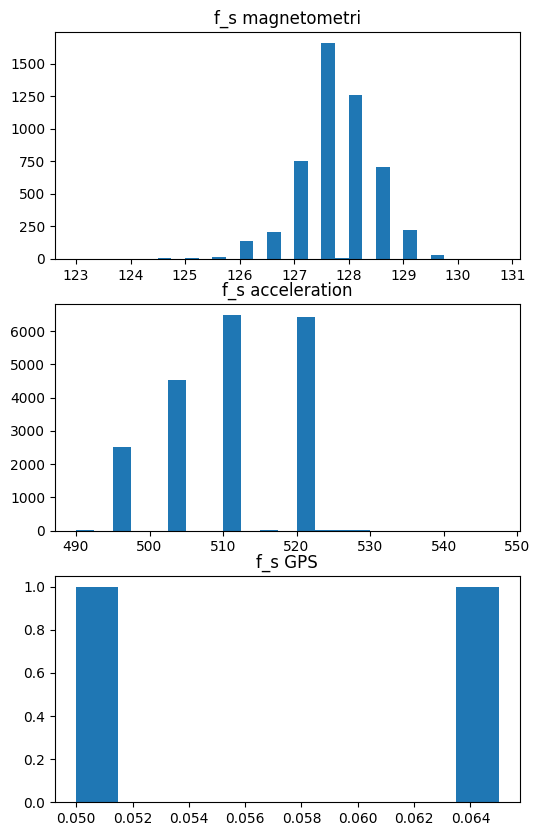

In [ ]:
# d) Piirrä aikaväleistä laskettujen taajuuksien histogrammit eri sensoreille. Vertaa tuloksia.
plt.figure(figsize=(6,10))
plt.subplot(3,1,1)
plt.hist(df_mag['f_s [hz]'],bins = np.arange(123,131,0.25))
plt.title('f_s magnetometri')
plt.subplot(3,1,2)
plt.hist(df_acc['f_s [hz]'],bins = np.arange(490,550,2.5))
plt.title('f_s acceleration')
#df_loc['f_s [hz]']
plt.subplot(3,1,3)
plt.hist(df_loc['f_s [hz]'])
plt.title('f_s GPS')


#Johtopäätös:
#Eri sensorit ovat erilaisia. Näytteenottotaajuus (sämpläystaajuus) vaihtelee ja myöskin sen jakauma on hyvin erilainen eri sensoreilla. 


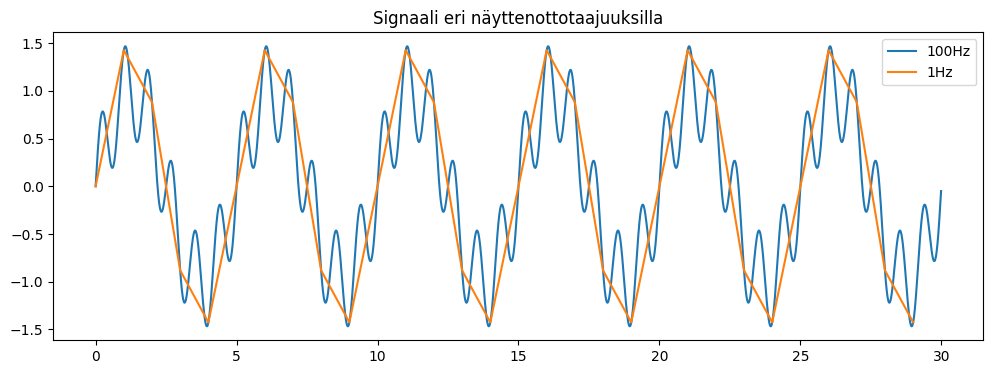

In [61]:
# Tehtävä 10
# Tarkastellaan signaalia
# s(t)=sin(2π⋅0,2t)+0,5sin(2π⋅1,2t).
# a) Muodosta signaali Pythonilla 100 Hz:n näytteenottotaajuudella aikavälillä 0≤t<30 s.

pi = np.pi
f_s = 100 #Näytteenottotaajuus
t_s = 1/f_s #Näytteenottoväli
t_start = 0
t_end = 30
t = np.arange(t_start,t_end,t_s) #Signaalin aikaleimat 100Hz taajuudella
s = np.sin(2*pi*0.2*t) + 0.5*np.sin(2*pi*1.2*t)

# b) Poimi siitä havainnot sekunnin välein ja piirrä ne alkuperäisen signaalin päälle.
t_1= t[::100] #Joka sadas havainto, eli sekunnin välein
s_1= s[::100]

plt.figure(figsize=(12,4))
plt.plot(t,s,label = '100Hz')
plt.plot(t_1,s_1,label = '1Hz')
plt.legend()
plt.title('Signaali eri näyttenottotaajuuksilla')
plt.show()

# c) Mitkä alkuperäisen signaalin taajuudet voidaan erottaa 1 Hz:n näytteistyksellä?
#Nyqvistin teoreeman mukaan suurin havaittava taajuus on näytteenottotaajuuden puolikas.
#Eli tässä tapauksessa 0.5 Hz



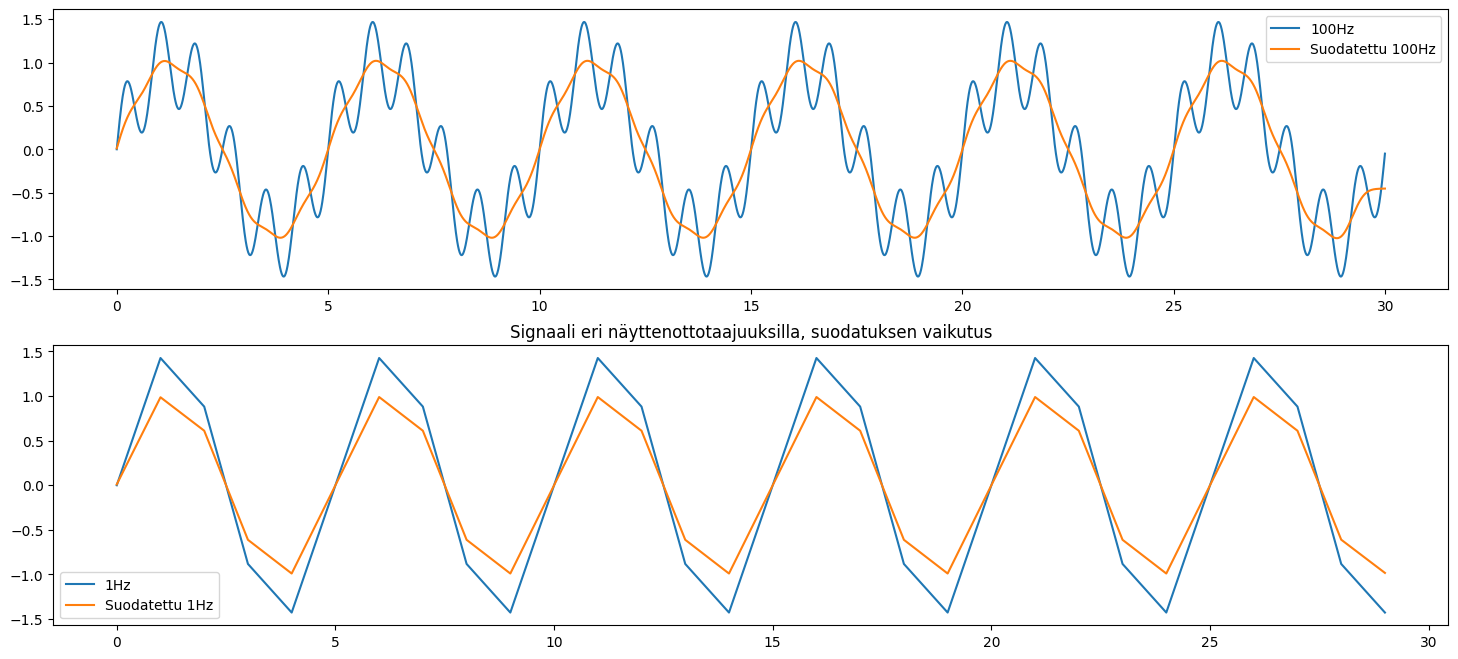

In [62]:
# d) Suodata korkeataajuinen komponentti pois ennen näytteenottotaajuuden pienentämistä. 
    # Valitse alipäästösuodatin, joka säilyttää 0,2 Hz:n komponentin ja vaimentaa 1,2 Hz:n komponenttia. 
    # Perustele suodattimen valinta ja tarkista sen vaikutus komponenttien amplitudeihin.
# e) Vertaa suodatettua ja suodattamatonta tulosta. Selitä havaintosi.

#Tuodaan filtterifunktiot
from scipy.signal import butter,filtfilt
def butter_lowpass_filter(data, cutoff, fs, nyq, order):
    normal_cutoff = cutoff / nyq
    # Get the filter coefficients
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    y = filtfilt(b, a, data)
    return y

def butter_highpass_filter(data, cutoff, fs, nyq, order):
    normal_cutoff = cutoff / nyq
    # Get the filter coefficients 
    b, a = butter(order, normal_cutoff, btype='high', analog=False)
    y = filtfilt(b, a, data)
    return y


#Filtterien parametrit
T = t_end - t_start #Koko datan pituus
n = len(s) #Datapisteiden lukumäärä
#f_s  #Näytteenottotaajuus (olettaen vakioksi)
nyq = f_s/2 #Nyqvistin taajuus
order = 3 #Kertaluku
cutoff = 0.8 #Cutt-off taajuus

#Suodatus:
s_filt = butter_lowpass_filter(s, cutoff, f_s, nyq, order) #Suodatettu signaali (100 Hz näytteenottotaajuus)
#Näytteistys 1Hz taajuudella:
s_filt_1 = s_filt[::100]

plt.figure(figsize=(18,8))
plt.subplot(2,1,1)
plt.plot(t,s,label = '100Hz')
plt.plot(t,s_filt,label = 'Suodatettu 100Hz')
plt.legend()
plt.subplot(2,1,2)
plt.plot(t_1,s_1,label = '1Hz')
plt.plot(t_1,s_filt_1,label = 'Suodatettu 1Hz')
plt.legend()
plt.title('Signaali eri näyttenottotaajuuksilla, suodatuksen vaikutus')
plt.show()